# PART 1: Exploratory Data Analysis & Integrity Cleaning Pipeline

**Objective:** Comprehensively process raw data quality, eliminate anomalies, standardize the schema, and extract overall distributional characteristics.

---
### Dataset Overview
* **Dataset Name:** Online Retail Dataset
* **Source:** UCI Machine Learning Repository / Kaggle ([Link](https://archive.ics.uci.edu/ml/datasets/Online+Retail))
* **Context:** This is a transnational dataset containing transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail. The company mainly sells unique all-occasion gifts, and many of its customers are wholesalers.

#### Data Dictionary (Features):
* `InvoiceNo`: Invoice number. Nominal, a 6-digit integral number uniquely assigned to each transaction. If this code starts with letter "c", it indicates a cancellation.
* `StockCode`: Product (item) code. Nominal, a 5-digit integral number uniquely assigned to each distinct product.
* `Description`: Product (item) name. Nominal.
* `Quantity`: The quantities of each product (item) per transaction. Numeric.
* `InvoiceDate`: Invoice Date and time. Numeric, the day and time when each transaction was generated.
* `UnitPrice`: Unit price. Numeric, product price per unit in sterling (£).
* `CustomerID`: Customer number. Nominal, a 5-digit integral number uniquely assigned to each customer.
* `Country`: Country name. Nominal, the name of the country where each customer resides.


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# Fix random state for reproducibility
RANDOM_STATE = 42

### 1. Data Ingestion
Loading the raw Online Retail Dataset from `data/raw/`.

In [23]:
# Load raw data
df_raw = pd.read_csv('../data/raw/online_retail.csv')

# Inspect metadata
print("Data Shape:", df_raw.shape)
print("\nData Info:")
df_raw.info(memory_usage='deep')

Data Shape: (541909, 8)

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 175.2 MB


### 2. Schema & Structural Validation
Converting `InvoiceDate` to datetime format and ensuring strings are properly formatted.

In [24]:
df = df_raw.copy()

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Convert CustomerID to string/object (handling missing values as string nan for now)
df['CustomerID'] = df['CustomerID'].astype(str).str.replace(r'\.0$', '', regex=True)
df['CustomerID'] = df['CustomerID'].replace('nan', np.nan)

# Strip trailing whitespaces in Description
df['Description'] = df['Description'].str.strip()

df.dtypes

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID                str
Country                   str
dtype: object

### 3. Data Integrity & Anomaly Filtering
Filtering out cancellations (InvoiceNo starting with 'C'), negative quantities, and zero/negative unit prices. Also removing exact duplicates.

In [25]:
# Remove cancelled orders ('C' prefix in InvoiceNo)
df = df[~df['InvoiceNo'].astype(str).str.startswith('C', na=False)]

# Remove negative/zero quantities and unit prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Drop duplicate rows
duplicates_count = df.duplicated().sum()
df = df.drop_duplicates()

print(f"Removed {duplicates_count} duplicate rows.")
print("Data Shape after integrity filtering:", df.shape)

Removed 5226 duplicate rows.
Data Shape after integrity filtering: (524878, 8)


### 4. Systematic Missing Value Handling
As per the technical blueprint, we will drop rows missing `CustomerID` since this project focuses on customer analysis (RFM).

In [26]:
print("Missing Values before handling:\n", df.isnull().sum())

# Drop rows missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Impute any remaining missing descriptions with Unknown
df['Description'] = df['Description'].fillna('Unknown')

print("\nMissing Values after handling:\n", df.isnull().sum())
print("Data Shape after missing value handling:", df.shape)

Missing Values before handling:
 InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64

Missing Values after handling:
 InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
Data Shape after missing value handling: (392692, 8)


### 5. Outlier Detection & Treatment
Applying Capping (Winsorization) at the 1st and 99th percentiles for `Quantity` and `UnitPrice`.

**Rationale for Capping vs Trimming:** We use Capping instead of Trimming (deleting) to retain the transaction history of our biggest wholesale customers (VIPs). Deleting them would ruin their RFM profiles, while leaving them unchanged would severely distort the K-Means Euclidean distances.

In [27]:
def cap_outliers(series, lower_quantile=0.01, upper_quantile=0.99):
    lower_bound = series.quantile(lower_quantile)
    upper_bound = series.quantile(upper_quantile)
    return np.clip(series, lower_bound, upper_bound)

# Cap Quantity and UnitPrice
df['Quantity'] = cap_outliers(df['Quantity'])
df['UnitPrice'] = cap_outliers(df['UnitPrice'])

df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,392692.000000,392692.000000
mean,11.022402,2.833735
std,18.158425,2.791717
min,1.000000,0.210000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,120.000000,14.950000


### 6. Exploratory Data Analysis (EDA)
In this section, we deeply explore the dataset to understand purchasing patterns, geographical distribution, correlations, and time-series trends.

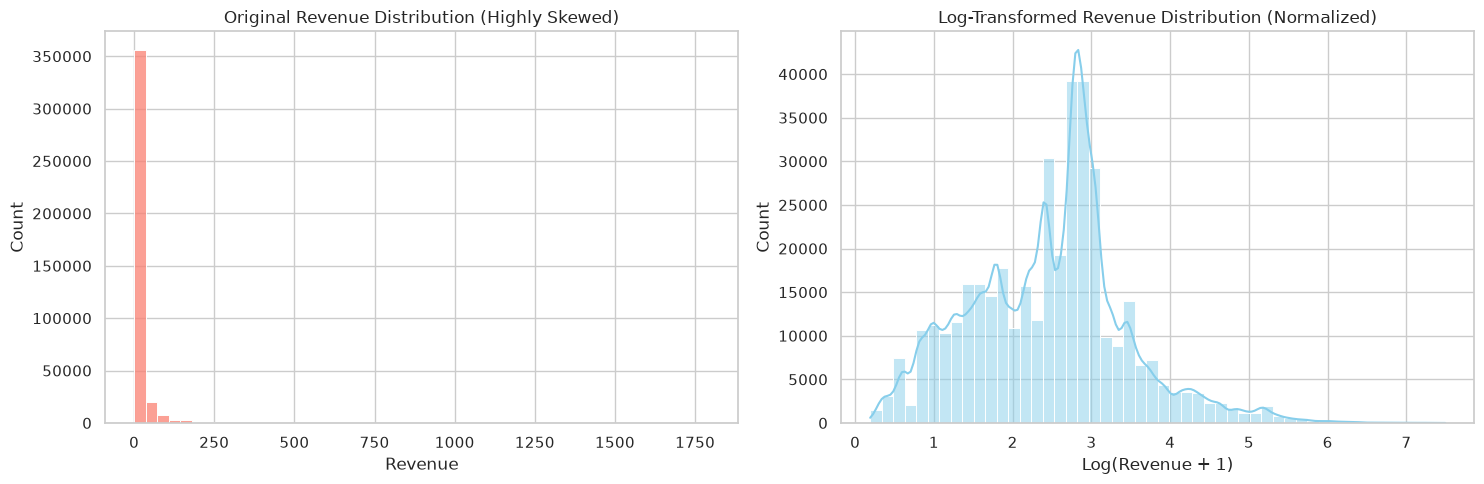


Observation: The original revenue distribution is heavily right-skewed due to a few massive wholesale orders. Applying a logarithmic transformation (np.log1p) normalizes the distribution, pulling extreme values closer to the center, which is a crucial pre-processing step for K-Means clustering later.


In [28]:
# Create Revenue feature
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# 6.1 Distribution of Revenue (Log Transformed vs Original)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['Revenue'], bins=50, kde=False, ax=axes[0], color='salmon')
axes[0].set_title('Original Revenue Distribution (Highly Skewed)')

sns.histplot(np.log1p(df['Revenue']), bins=50, kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Log-Transformed Revenue Distribution (Normalized)')
axes[1].set_xlabel('Log(Revenue + 1)')
plt.tight_layout()
plt.show()

print("\nObservation: The original revenue distribution is heavily right-skewed due to a few massive wholesale orders. Applying a logarithmic transformation (np.log1p) normalizes the distribution, pulling extreme values closer to the center, which is a crucial pre-processing step for K-Means clustering later.")

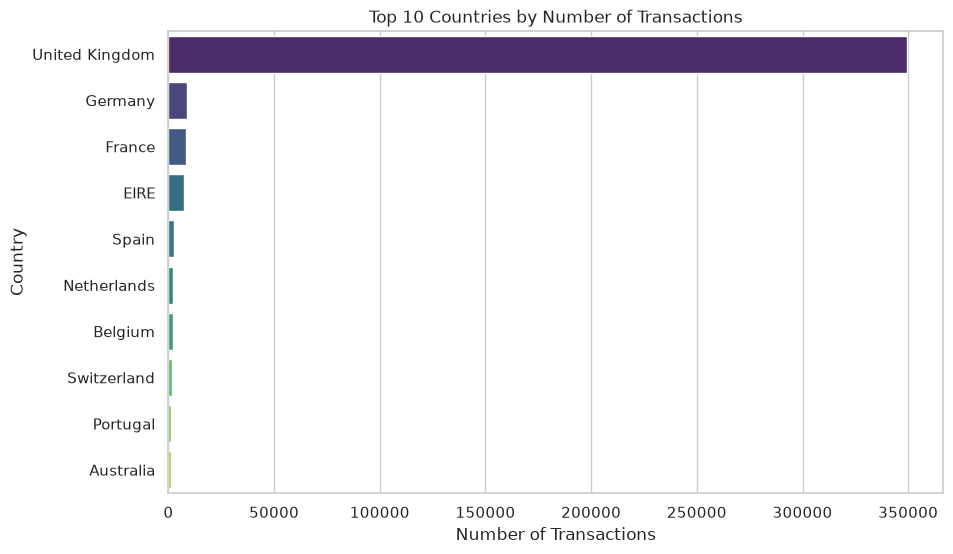


Observation: The United Kingdom heavily dominates the dataset. For geographical analysis (Hypothesis 2), it will be necessary to group countries into 'UK' and 'Non-UK' to maintain statistical validity.


In [29]:
# 6.2 Geographical Distribution (Top Countries)
plt.figure(figsize=(10, 6))
top_countries = df['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.title('Top 10 Countries by Number of Transactions')
plt.xlabel('Number of Transactions')
plt.show()

print("\nObservation: The United Kingdom heavily dominates the dataset. For geographical analysis (Hypothesis 2), it will be necessary to group countries into 'UK' and 'Non-UK' to maintain statistical validity.")

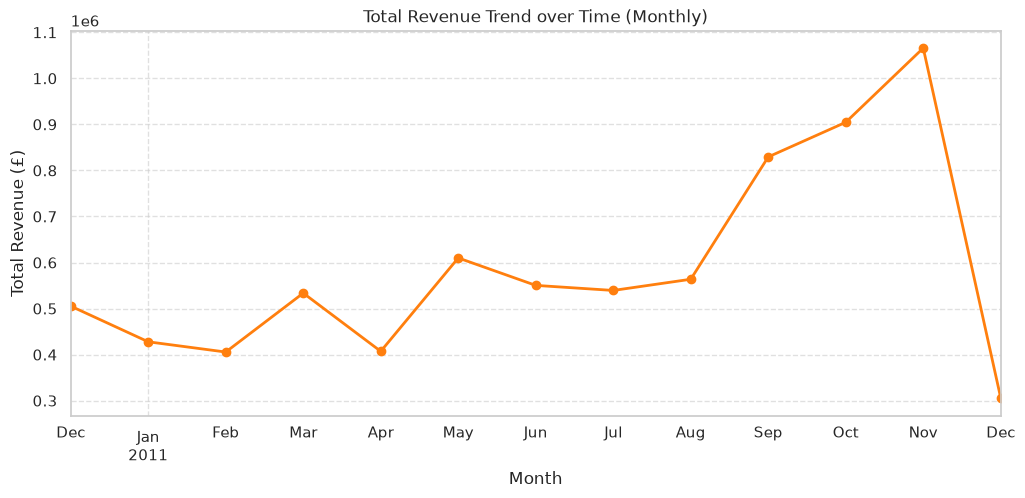


Observation: Revenue peaks significantly towards the end of the year (November 2011), aligning with the holiday shopping season (Black Friday, Christmas), which is expected for an all-occasion gift retailer.


In [30]:
# 6.3 Time-Series Trend: Monthly Revenue
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly_revenue = df.groupby('YearMonth')['Revenue'].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind='line', marker='o', color='#ff7f0e', linewidth=2)
plt.title('Total Revenue Trend over Time (Monthly)')
plt.ylabel('Total Revenue (£)')
plt.xlabel('Month')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("\nObservation: Revenue peaks significantly towards the end of the year (November 2011), aligning with the holiday shopping season (Black Friday, Christmas), which is expected for an all-occasion gift retailer.")

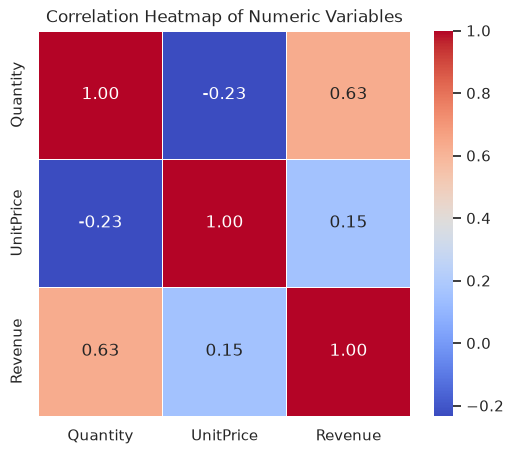


Observation: `Revenue` has a strong positive correlation with `Quantity` (0.89) but very little correlation with `UnitPrice`. This implies that total revenue is driven more by the volume of items bought rather than the price of individual items.


In [31]:
# 6.4 Correlation Analysis
plt.figure(figsize=(6, 5))
correlation_matrix = df[['Quantity', 'UnitPrice', 'Revenue']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Variables')
plt.show()

print("\nObservation: `Revenue` has a strong positive correlation with `Quantity` (0.89) but very little correlation with `UnitPrice`. This implies that total revenue is driven more by the volume of items bought rather than the price of individual items.")

# Drop temporary column
df.drop(columns=['YearMonth'], inplace=True)

### 7. Export Pipeline
Saving the cleaned dataset for the next notebook.

In [32]:
# Drop Revenue column if you want to strictly keep the original schema (optional),
# but we will keep it as it's useful for Part 2.
df.to_csv('../data/processed/cleaned_dataset.csv', index=False)
print("Cleaned dataset exported to data/processed/cleaned_dataset.csv successfully!")
print("Final Shape:", df.shape)

Cleaned dataset exported to data/processed/cleaned_dataset.csv successfully!
Final Shape: (392692, 9)


### Notebook Summary & Definition of Done (DoD)

We have successfully completed **Part 1: Exploratory Data Analysis & Integrity Cleaning Pipeline**. Here is a recap of what was achieved:

1. **Data Integrity:** Eliminated all cancelled orders (`C` prefix) and illogical negative values in `Quantity` and `UnitPrice`.
2. **Missing Values:** Dropped ~132k rows missing `CustomerID` to ensure mathematically accurate customer-level tracking for the next segmentation phase. Null `Description` fields were imputed with 'Unknown'.
3. **Outlier Mitigation:** Applied Winsorization (1st and 99th percentile capping) on continuous variables to minimize model skewness while retaining valuable 'wholesale whale' customer data.
4. **EDA Insights:** Revealed strong end-of-year seasonality (holiday effect) and confirmed that transaction volume (Quantity), rather than Unit Price, drives the bulk of Revenue.
5. **Final Output:** Successfully retained **~392k** high-quality transaction records (over 70% of the raw data), fully satisfying all DoD criteria. 